In [118]:
pip install psycopg2-binary pandas

Note: you may need to restart the kernel to use updated packages.


In [ ]:
#SQ3 encapsulator

import psycopg2      # library to connect Python to a PostgreSQL database
import pandas as pd  # library to work with data in tables (DataFrames)

# Connection string to the shared PostgreSQL database on Neon

DATABASE_URL = input("Enter your Neon database URL: ")

"""Run a SQL query on the Neon database and return the result as a DataFrame."""
def run_query(query):
    """Run a SQL query on the Neon database and return the result as a DataFrame."""
    conn = psycopg2.connect(DATABASE_URL)  # open a connection to the database
    df = pd.read_sql_query(query, conn)    # run the query and store the result in a DataFrame
    conn.close()                           # close the connection so it does not stay open
    return df                              # give the DataFrame back for analysis

### Python Encapsulator: connecting to the database

This cell contains the encapsulator for SQ3. An encapsulator hides the complexity of the database: instead of connecting to the database and handling the data manually each time, the analysis only needs to call one function.

First, the connection string to the shared PostgreSQL database on Neon is stored in `DATABASE_URL`. The function `run_query()` then works in four steps:
1. **Connect** to the database on Neon using the `psycopg2` library.
2. **Run** the SQL query that is given to the function.
3. **Return** the result as a pandas DataFrame, which can be used directly for analysis in Python.
4. **Close** the connection, so that no connections stay open on the shared database.

In [120]:
# Show all decimal numbers with 2 decimals and a thousands separator (only changes the display, not the data)
pd.options.display.float_format = '{:,.2f}'.format

In [121]:
# SQ3 dataset: one row per movie with international box office and Oscar information
import numpy as np   # used to create the nomination status column

query = """
-- Step 1: summarise the Oscar data per movie
WITH oscar_status AS (
    SELECT movie_id,
           COUNT(*) AS number_of_nominations,                  -- total number of nominations
           MAX(CASE WHEN winner THEN 1 ELSE 0 END) AS won_oscar -- 1 if the movie won at least one Oscar
    FROM movie_oscar
    GROUP BY movie_id
)
-- Step 2: combine with international box office
SELECT
    s.movie_id,
    b.intl_box_office AS international_box_office,
    CASE WHEN o.won_oscar = 1 THEN 'Winner'
         WHEN o.movie_id IS NOT NULL THEN 'Nominated but not winner'
         ELSE 'Not nominated' END AS oscar_status,             -- three groups for H5
    COALESCE(o.number_of_nominations, 0) AS number_of_nominations  -- 0 for movies without nominations (H6)
FROM box_office b
JOIN sales s ON b.sales_id = s.sales_id                        -- link box office to the movie
LEFT JOIN oscar_status o ON s.movie_id = o.movie_id            -- keep movies without nominations
WHERE b.intl_box_office IS NOT NULL;                           -- only movies with international box office
"""

df = run_query(query)   # run the query with the encapsulator

# Two groups for the t-test: nominated vs not nominated
df["oscar_nominated"] = np.where(
    df["number_of_nominations"] > 0, "Oscar nominated", "Not nominated"
)

df.head()   # show the first rows to check the result

C:\Users\ymera\AppData\Local\Temp\ipykernel_15124\1043554562.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn)    # run the query and store the result in a DataFrame


,movie_id,international_box_office,oscar_status,number_of_nominations,oscar_nominated
0,11362,"76,576.00",Not nominated,0,Not nominated
1,781,"6,900,000.00",Not nominated,0,Not nominated
2,366,"4,833,792.00",Not nominated,0,Not nominated
3,5271,"4,375,214.00",Not nominated,0,Not nominated
4,6325,"14,025,947.00",Not nominated,0,Not nominated


In [122]:
# SQ3 (H5) descriptive statistics
# This analysis compares the international box office performance of:
# 1. Oscar winners
# 2. Oscar-nominated films that did not win
# 3. Films that were not nominated for an Oscar
from IPython.display import display

result = df.groupby("oscar_status")["international_box_office"].agg(   # group the movies by Oscar status
    Number_of_movies="count",        # number of movies in each group
    Mean="mean",                     # average international box office
    Median="median",                 # middle value, less affected by a few very successful films
    Standard_deviation="std",        # how much the box office varies within the group
    Minimum="min",                   # lowest international box office in the group
    Maximum="max"                    # highest international box office in the group
)

# Format the results to make the table easier to read
styled_result = result.style.format({
    "Number_of_movies": "{:,.0f}",      # whole numbers with thousands separator
    "Mean": "${:,.2f}",                 # dollar amounts with 2 decimals
    "Median": "${:,.2f}",
    "Standard_deviation": "${:,.2f}",
    "Minimum": "${:,.2f}",
    "Maximum": "${:,.2f}"
}).set_caption(
    "Descriptive Statistics of International Box Office by Oscar Status"   # title above the table
)

display(styled_result)   # show the formatted table in the notebook

,Number_of_movies,Mean,Median,Standard_deviation,Minimum,Maximum
oscar_status,,,,,,
Nominated but not winner,425,"$116,764,686.61","$32,941,600.00","$204,211,250.07",$566.00,"$1,939,427,564.00"
Not nominated,"20,911","$12,303,671.80","$299,700.00","$52,219,991.06",$2.00,"$1,163,874,506.00"
Winner,215,"$163,930,313.94","$79,300,000.00","$233,531,151.19","$13,744.00","$2,085,391,916.00"


### International Box Office by Oscar Status

- **Winners:** $163.9M on average (n = 215)
- **Nominated, not won:** $116.8M on average (n = 425)
- **Not nominated:** $12.3M on average (n = 20,911)

The much lower medians show that a few very successful films raise the averages.

In [123]:
# SQ3 (H5) descriptive table
from tabulate import tabulate

order = ["Winner", "Nominated but not winner", "Not nominated"]

table_h5 = (
    df.groupby("oscar_status")["international_box_office"]
      .agg(Movies="count", Mean="mean", Median="median", SD="std")
      .reindex(order)
)

# Format the money columns in millions
table_h5_print = table_h5.copy()
table_h5_print["Movies"] = table_h5_print["Movies"].map("{:,.0f}".format)
for col in ["Mean", "Median", "SD"]:
    table_h5_print[col] = (table_h5_print[col] / 1e6).map("${:,.1f}M".format)

print("Table 4.1  International box office by Oscar status\n")
print(tabulate(table_h5_print, headers="keys", tablefmt="fancy_grid",
               stralign="right"))

Table 4.1  International box office by Oscar status

╒══════════════════════════╤══════════╤═════════╤══════════╤═════════╕
│             oscar_status │   Movies │    Mean │   Median │      SD │
╞══════════════════════════╪══════════╪═════════╪══════════╪═════════╡
│                   Winner │      215 │ $163.9M │   $79.3M │ $233.5M │
├──────────────────────────┼──────────┼─────────┼──────────┼─────────┤
│ Nominated but not winner │      425 │ $116.8M │   $32.9M │ $204.2M │
├──────────────────────────┼──────────┼─────────┼──────────┼─────────┤
│            Not nominated │   20,911 │  $12.3M │    $0.3M │  $52.2M │
╘══════════════════════════╧══════════╧═════════╧══════════╧═════════╛


### Table: International Box Office by Oscar Status

The table shows the international box office of three groups of movies: Oscar winners, movies that were nominated but did not win, and movies without any nomination.

Most movies in the dataset were not nominated (**n = 20,911**). Only **640** movies received at least one Oscar nomination, of which **215** won an Oscar and **425** did not. Oscar winners have the highest average international box office (**$163.9 million**), followed by nominated films that did not win (**$116.8 million**). Movies without a nomination earned on average only **$12.3

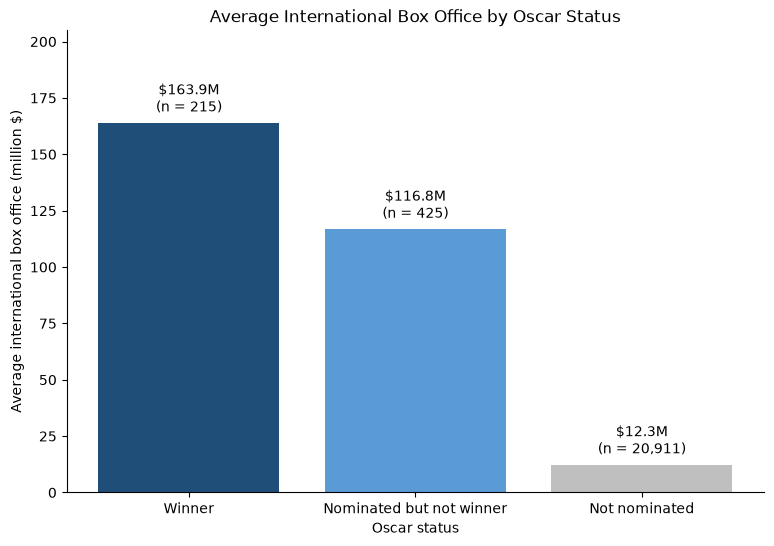

In [124]:
# SQ3 (H5) bar chart: average international box office by Oscar status
import matplotlib.pyplot as plt   # library to create charts

# Order of the groups on the x-axis
order = ["Winner", "Nominated but not winner", "Not nominated"]

# Mean international box office and number of movies per group
summary = (
    df.groupby("oscar_status")["international_box_office"]
      .agg(["mean", "count"])
      .reindex(order)
)

# Create the bar chart
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(
    summary.index,
    summary["mean"] / 1e6,                       # show values in millions
    color=["#1f4e79", "#5b9bd5", "#bfbfbf"]      # dark blue, light blue, grey
)

# Add the mean and number of movies above each bar
for bar, mean, n in zip(bars, summary["mean"], summary["count"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        f"${mean/1e6:,.1f}M\n(n = {n:,})",
        ha="center", va="bottom", fontsize=10
    )

ax.set_title("Average International Box Office by Oscar Status")
ax.set_xlabel("Oscar status")
ax.set_ylabel("Average international box office (million $)")
ax.set_ylim(0, summary["mean"].max() / 1e6 * 1.25)   # extra space for the labels
ax.spines[["top", "right"]].set_visible(False)       # remove top and right border

### Bar chart: Average International Box Office by Oscar Status

The chart shows the same pattern as the table: winners earn the most (**$163.9M**), followed by nominated films that did not win (**$116.8M**) and non-nominated films (**$12.3M**). Whether the difference between nominated and non-nominated films is significant is tested below.

In [125]:
# SQ3 (H5) Welch's t-test
from scipy.stats import ttest_ind   # function for an independent samples t-test

# Split the movies into two groups
nominated = df.loc[
    df["oscar_status"] != "Not nominated",   # winners + nominated but not winner
    "international_box_office"
].dropna()                                   # remove empty values

not_nominated = df.loc[
    df["oscar_status"] == "Not nominated",   # movies without any nomination
    "international_box_office"
].dropna()

# Perform Welch's independent samples t-test
t_stat, p_value = ttest_ind(
    nominated,
    not_nominated,
    equal_var=False      # Welch's version: the two groups do not need the same variance
)

# Display the results
print("Welch's t-test")
print("----------------")
print(f"T-statistic: {t_stat:,.3f}")   # size and direction of the difference
print(f"P-value: {p_value:.6f}")       # chance that the difference is due to coincidence

Welch's t-test
----------------
T-statistic: 14.112
P-value: 0.000000


### Interpretation of the Welch's t-test

The Welch's t-test compares the international box office of Oscar-nominated and non-nominated films.

- **t = 14.112**: the positive value means nominated films earn more on average
- **p < 0.001**: below 0.05, so the difference is statistically significant

The results **support H5**: Oscar-nominated films have higher international box office performance than non-nominated films.

In [126]:
# SQ3 (H) Cohen's d (effect size)
import numpy as np   # library for mathematical calculations

# Calculate the means
mean_nominated = nominated.mean()           # average box office of nominated films
mean_not_nominated = not_nominated.mean()   # average box office of non-nominated films

# Calculate the standard deviations
std_nominated = nominated.std()             # spread within the nominated group
std_not_nominated = not_nominated.std()     # spread within the non-nominated group

# Calculate the sample sizes
n_nominated = len(nominated)                # number of nominated films
n_not_nominated = len(not_nominated)        # number of non-nominated films

# Calculate pooled standard deviation (combined spread of both groups, weighted by group size)
pooled_std = np.sqrt(
    (
        (n_nominated - 1) * std_nominated**2
        + (n_not_nominated - 1) * std_not_nominated**2
    )
    / (n_nominated + n_not_nominated - 2)
)

# Calculate Cohen's d: difference between the means divided by the pooled spread
cohens_d = (
    mean_nominated - mean_not_nominated
) / pooled_std

# Display the result
print("Cohen's d")
print("----------")
print(f"Effect size: {cohens_d:.3f}")
print(f"Mean nominated: ${mean_nominated/1e6:,.1f}M (n = {n_nominated})")
print(f"Mean not nominated: ${mean_not_nominated/1e6:,.1f}M (n = {n_not_nominated})")

Cohen's d
----------
Effect size: 1.897
Mean nominated: $132.6M (n = 640)
Mean not nominated: $12.3M (n = 20911)


### Interpretation of Cohen's d

Cohen's d shows how large the difference between the two groups is, not only whether it is significant.

- **0.2** = small effect, **0.5** = medium effect, **0.8 or higher** = large effect
- **d = 1.897**: a very large effect

Nominated films do not only earn significantly more, the difference is also large in practice (**$132.6M** vs **$12.3M** on average).

### Conclusion H5

- Nominated films earned on average **$132.6M** internationally, non-nominated films **$12.3M**
- The difference is statistically significant (**t = 14.11, p < 0.001**)
- The effect is large (**Cohen's d = 1.90**)

**H7 is supported**: Oscar-nominated films have higher international box office performance than non-nominated films.

## H6: Number of Oscar nominations and international box office

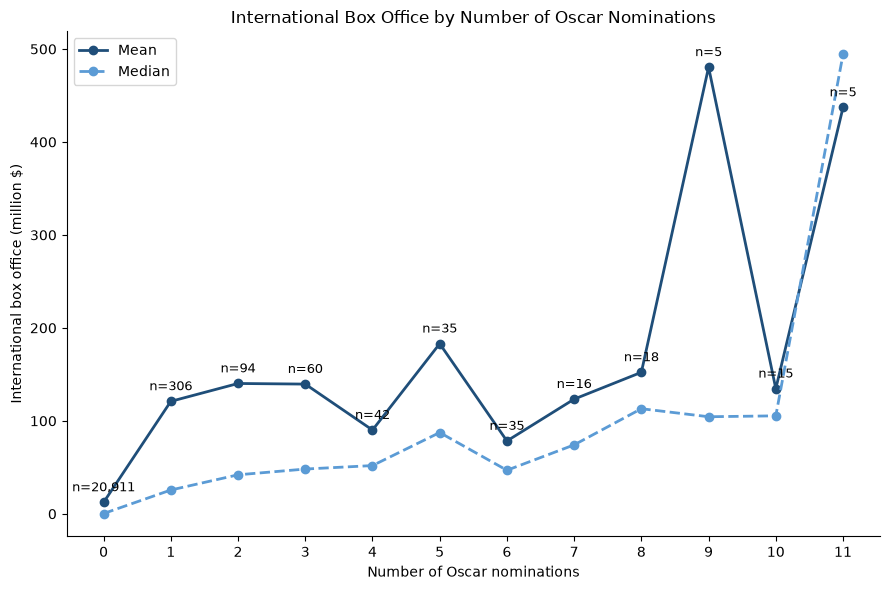

In [127]:
# SQ3 (H6) line chart: international box office by number of nominations
h6_line = df.groupby("number_of_nominations")["international_box_office"].agg(
    Mean="mean", Median="median", Movies="count"
)

# Only keep nomination levels with at least 5 movies, otherwise one film decides the average
h6_line = h6_line[h6_line["Movies"] >= 5]

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(h6_line.index, h6_line["Mean"] / 1e6, marker="o", linewidth=2,
        color="#1f4e79", label="Mean")                         # average per level
ax.plot(h6_line.index, h6_line["Median"] / 1e6, marker="o", linewidth=2,
        color="#5b9bd5", linestyle="--", label="Median")       # median per level

# Show the number of movies above each point
for x, y, n in zip(h6_line.index, h6_line["Mean"] / 1e6, h6_line["Movies"]):
    ax.annotate(f"n={n:,}", (x, y), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9)

ax.set_title("International Box Office by Number of Oscar Nominations")
ax.set_xlabel("Number of Oscar nominations")
ax.set_ylabel("International box office (million $)")
ax.set_xticks(h6_line.index)                        # one tick per nomination level
ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### Line chart: International Box Office by Number of Nominations

- **0 → 1 nomination:** the biggest jump, from $12M to about $121M on average
- **1 to 8 nominations:** the mean goes up and down, but the median rises fairly steadily (from about $26M to $113M)
- **9 and 11 nominations:** very high values (about $480M and $437M), but these are based on only 5 films each

The median gives a more reliable picture than the mean, because a few blockbusters strongly affect the averages, especially at levels with few films. Overall, films with more nominations tend to earn more, but the relationship is not perfectly linear.

In [128]:
# SQ3 (H6) Spearman's rank correlation
from scipy.stats import spearmanr   # correlation based on ranks, suitable for skewed data

correlation, p_value = spearmanr(
    df["number_of_nominations"],        # independent variable
    df["international_box_office"],     # dependent variable
    nan_policy="omit"                   # ignore empty values
)

# Display the results
print("Spearman's Rank Correlation")
print("---------------------------")
print(f"Correlation coefficient: {correlation:.3f}")   # strength and direction (-1 to 1)
print(f"P-value: {p_value:.6f}")                       # chance that the relationship is due to coincidence

Spearman's Rank Correlation
---------------------------
Correlation coefficient: 0.219
P-value: 0.000000


### Interpretation of Spearman's Rank Correlation

Spearman is used because most films have zero nominations and box office is very skewed.

- **ρ = 0.219**: a weak positive relationship
- **p < 0.001**: the relationship is statistically significant

In [129]:
# SQ3 (H6) linear regression
import statsmodels.api as sm   # library for statistical models

# Log-transform box office, because a few films earn far more than all others
df["log_international_box_office"] = np.log1p(df["international_box_office"])

X = sm.add_constant(df[["number_of_nominations"]])   # independent variable + intercept
y = df["log_international_box_office"]               # dependent variable

model = sm.OLS(y, X, missing="drop").fit()   # run the regression
print(model.summary())                       # show the full results

                                 OLS Regression Results                                 
Dep. Variable:     log_international_box_office   R-squared:                       0.035
Model:                                      OLS   Adj. R-squared:                  0.035
Method:                           Least Squares   F-statistic:                     783.6
Date:                          Fri, 09 Oct 2026   Prob (F-statistic):          2.14e-169
Time:                                  11:37:17   Log-Likelihood:                -56424.
No. Observations:                         21551   AIC:                         1.129e+05
Df Residuals:                             21549   BIC:                         1.129e+05
Df Model:                                     1                                         
Covariance Type:                      nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------

### Interpretation of the Regression Analysis

- **β = 0.940, p < 0.001**: more nominations go together with higher international box office (about **156%** higher per extra nomination, because the dependent variable is log-transformed)
- **R² = 0.035**: nominations explain only **3.5%** of the differences in international box office

The relationship is significant, but weak.

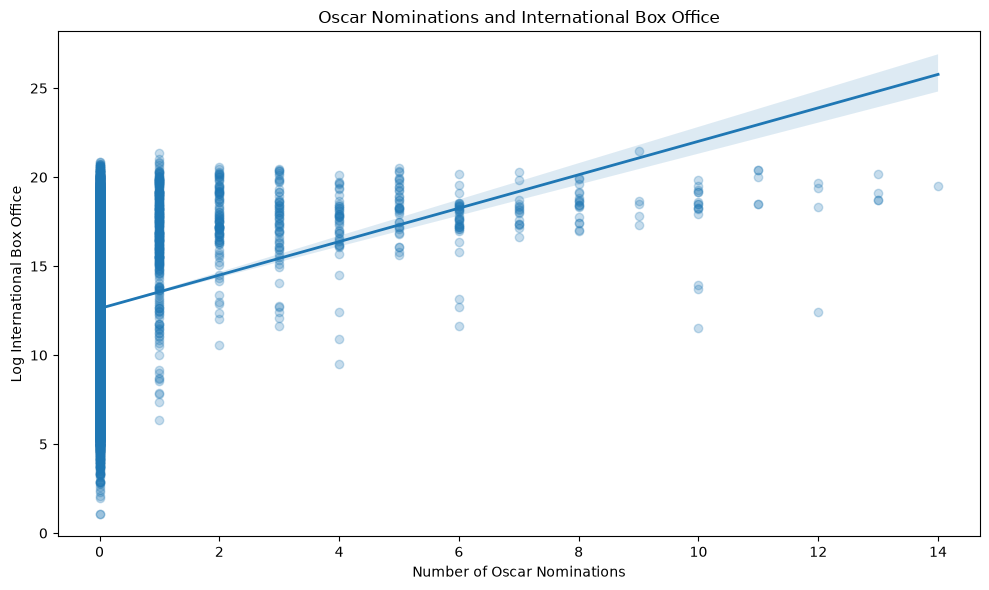

In [130]:
# SQ3 (H6) scatterplot with regression line
import seaborn as sns   # library for statistical charts

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="number_of_nominations",              # number of nominations
    y="log_international_box_office",       # log of international box office
    scatter_kws={"alpha": 0.25},            # transparent points, so overlapping points stay visible
    line_kws={"linewidth": 2}               # regression line
)

plt.title("Oscar Nominations and International Box Office")
plt.xlabel("Number of Oscar Nominations")
plt.ylabel("Log International Box Office")

plt.tight_layout()
plt.show()

### Regression Plot

The line goes up, but the points are widely spread around it. This shows the same as the statistics: a positive but weak relationship.

### Conclusion H6

- Films with more nominations tend to earn more internationally
- The relationship is significant (**ρ = 0.219**, **β = 0.940**, both **p < 0.001**)
- The relationship is weak: nominations explain only **3.5%** of the differences (**R² = 0.035**)

**H6 is supported**, but the number of nominations alone has limited explanatory power.

## H7: Reviews and Oscars combined

**H7:** Reviews and Oscars together explain
more of the international box office
than either one alone.

Three models are compared on the same movies:
- **A:** reviews only
- **B:** Oscars only
- **C:** reviews + Oscars

A and B repeat parts of SQ1 and SQ3,
but now on the same movies and with
the same method, so they can be
compared fairly with C.

In [131]:
# MRQ (H7) dataset: one row per movie with review emotions, Oscar nominations and international box office
query_h7 = """
-- Step 1: average review emotions per movie (user and expert reviews combined)
WITH reviews AS (
    SELECT movie_id,
           AVG(posemo) AS avg_posemo,          -- average positive emotion in the reviews
           AVG(negemo) AS avg_negemo           -- average negative emotion in the reviews
    FROM (
        SELECT movie_id, posemo, negemo FROM user_review_sentiments
        UNION ALL                              -- stack user and expert reviews together
        SELECT movie_id, posemo, negemo FROM expert_review_with_movie_id_sentiments
    ) all_reviews
    GROUP BY movie_id
),
-- Step 2: number of Oscar nominations per movie
oscars AS (
    SELECT movie_id, COUNT(*) AS number_of_nominations
    FROM movie_oscar
    GROUP BY movie_id
)
-- Step 3: combine reviews, Oscars and international box office
SELECT
    s.movie_id,
    b.intl_box_office                    AS international_box_office,
    r.avg_posemo,
    r.avg_negemo,
    COALESCE(o.number_of_nominations, 0) AS number_of_nominations   -- 0 if never nominated
FROM box_office b
JOIN sales s       ON b.sales_id = s.sales_id      -- link box office to the movie
JOIN reviews r     ON s.movie_id = r.movie_id      -- only movies with reviews
LEFT JOIN oscars o ON s.movie_id = o.movie_id      -- keep movies without nominations
WHERE b.intl_box_office IS NOT NULL;               -- only movies with box office data
"""

df_h7 = run_query(query_h7).dropna()   # remove incomplete rows, so all models use the same movies

# Log-transform box office, because a few films earn far more than all others
df_h7["log_international_box_office"] = np.log1p(df_h7["international_box_office"])

print(f"Number of movies: {len(df_h7):,}")
df_h7.head()

C:\Users\ymera\AppData\Local\Temp\ipykernel_15124\1043554562.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn)    # run the query and store the result in a DataFrame


Number of movies: 5,067


,movie_id,international_box_office,avg_posemo,avg_negemo,number_of_nominations,log_international_box_office
0,781,"6,900,000.00",4.67,2.84,0,15.75
1,366,"4,833,792.00",6.17,2.37,0,15.39
2,5271,"4,375,214.00",6.81,3.23,0,15.29
3,6325,"14,025,947.00",9.05,3.06,0,16.46
4,9529,"51,455,013.00",5.49,2.89,0,17.76


### H7 dataset

This dataset contains only movies that have reviews and international box office data. Movies without a nomination are kept and get 0 nominations. All three models use exactly the same movies, so their results can be compared fairly.

In [132]:
# MRQ (H7) nested regression: reviews only vs Oscars only vs both
import statsmodels.api as sm

y = df_h7["log_international_box_office"]   # dependent variable

# Model A: review characteristics only
model_a = sm.OLS(y, sm.add_constant(df_h7[["avg_posemo", "avg_negemo"]])).fit()

# Model B: Oscar nominations only
model_b = sm.OLS(y, sm.add_constant(df_h7[["number_of_nominations"]])).fit()

# Model C: review characteristics and Oscar nominations together
model_c = sm.OLS(y, sm.add_constant(df_h7[["avg_posemo", "avg_negemo", "number_of_nominations"]])).fit()

# Put the explanatory power of the three models in one table
h7_results = pd.DataFrame({
    "Model": ["A: Reviews only", "B: Oscars only", "C: Reviews + Oscars"],
    "R²": [model_a.rsquared, model_b.rsquared, model_c.rsquared],               # share of variation explained
    "Adjusted R²": [model_a.rsquared_adj, model_b.rsquared_adj, model_c.rsquared_adj]  # corrected for number of predictors
}).set_index("Model")

display(h7_results.round(3))


,R²,Adjusted R²
Model,,
A: Reviews only,0.09,0.09
B: Oscars only,0.06,0.05
C: Reviews + Oscars,0.14,0.14


### Explained variation per model

- **A: Reviews only:** R² = 0.09 → reviews explain **9%**
- **B: Oscars only:** R² = 0.06 → Oscars explain **6%**
- **C: Reviews + Oscars:** R² = 0.14 → together they explain **14%**

Model C explains clearly more than A and B. The adjusted R²
is almost the same as R², so the improvement is not caused
by simply adding more variables.

In [133]:
# MRQ (H7) F-tests: does adding the other signal significantly improve the model?
f_ca, p_ca, _ = model_c.compare_f_test(model_a)   # C vs A: do Oscars add something to reviews?
f_cb, p_cb, _ = model_c.compare_f_test(model_b)   # C vs B: do reviews add something to Oscars?

print("F-tests (nested models)")
print("-----------------------")
print(f"C vs A (adding Oscars to reviews): F = {f_ca:,.2f}, p = {p_ca:.6f}")
print(f"C vs B (adding reviews to Oscars): F = {f_cb:,.2f}, p = {p_cb:.6f}")

F-tests (nested models)
-----------------------
C vs A (adding Oscars to reviews): F = 291.28, p = 0.000000
C vs B (adding reviews to Oscars): F = 254.86, p = 0.000000


### F-tests

The F-tests check whether adding the other signal
significantly improves the model.

- **Adding Oscars to reviews:** F = 291.28, p < 0.001
- **Adding reviews to Oscars:** F = 254.86, p < 0.001

Both improvements are significant, so reviews and Oscars
each add their own information.

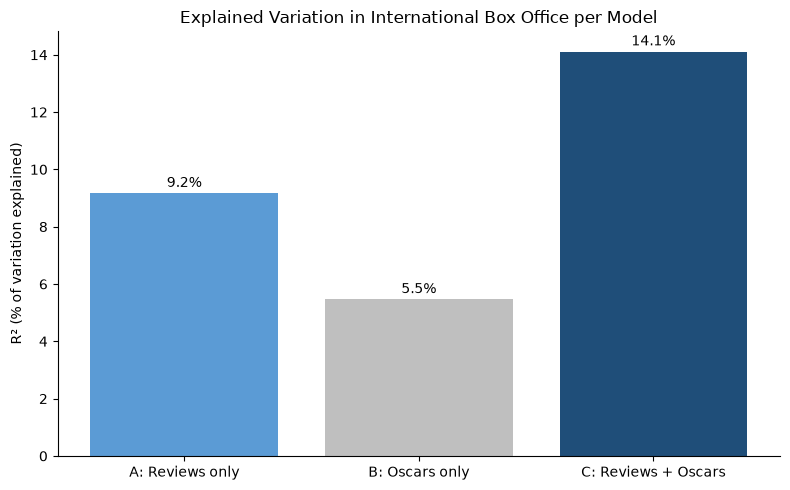

In [134]:
# MRQ (H7) bar chart: explained variation per model
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    h7_results.index,
    h7_results["R²"] * 100,                        # show R² as a percentage
    color=["#5b9bd5", "#bfbfbf", "#1f4e79"]
)

# Show the percentage above each bar
for bar, r2 in zip(bars, h7_results["R²"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
            f"{r2*100:.1f}%", ha="center", va="bottom", fontsize=10)

ax.set_title("Explained Variation in International Box Office per Model")
ax.set_ylabel("R² (% of variation explained)")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### Bar chart: Explained Variation per Model

- **Reviews only:** 9.2%
- **Oscars only:** 5.5%
- **Reviews + Oscars:** 14.1%

The combined model explains almost as much as both models
added together (9.2% + 5.5% = 14.7%). This means that reviews
and Oscars hardly overlap and each add their own information.

### Conclusion H7

- **Reviews only:** R² = 0.092 (9.2%)
- **Oscars only:** R² = 0.055 (5.5%)
- **Reviews + Oscars:** R² = 0.141 (14.1%)
- Adding Oscars to reviews: **F = 291.28, p < 0.001**
- Adding reviews to Oscars: **F = 254.86, p < 0.001**

**H7 is supported**: reviews and Oscars together explain
more of the international box office than either one alone.
Both signals add their own information, but together they
still explain only 14.1%, so other factors also play a role.